In [1]:
pip install -U mplhep

  Using cached mplhep-1.3.3-py3-none-any.whl.metadata (9.5 kB)


  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)


Using cached mplhep-1.3.3-py3-none-any.whl (93 kB)
Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)


  Attempting uninstall: matplotlib


    Found existing installation: matplotlib 3.10.8
    Uninstalling matplotlib-3.10.8:


...

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

  Attempting uninstall: mplhep
    Found existing installation: mplhep 1.1.2
    Uninstalling mplhep-1.1.2:
      Successfully uninstalled mplhep-1.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mplhep]


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)
from sidm.tools import utilities #scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()

In [3]:
title_name= "1 LJ CR" # title = r"1 LJ CR $\eta-\phi$ Veto"
ratio  = 6.616/62.061775847
# ratio = 1
channel_name = "cr_Zmumu_noLJ" ##chnage the selection depending on what you want to plot 
#"cr_1egmOr1mu_lj"
TT = functions.get_bg_file_names("TTJets")
DY = functions.get_bg_file_names("DYJetsToLL")
QCD = functions.get_bg_file_names("QCD")
DB = functions.get_bg_file_names("Diboson")
data = functions.get_data_files()
data =  [x for x in data if "C" in x]
folder_name = f"OutputFiles/{channel_name}"
sum_data_all= utilities.sum_hist(data, folder_name)
summed_QCD = utilities.sum_hist(QCD, folder_name)
summed_TT  = utilities.sum_hist(TT,  folder_name)
summed_DY  = utilities.sum_hist(DY, folder_name)
summed_DB  = utilities.sum_hist(DB,  folder_name)

In [4]:
histogram_name="mu_lj_pfMu_max_trkNumPixelHits"
binning = 1j
sum_bg_qcd = ratio * functions.isM(summed_QCD[histogram_name][channel_name, ::binning])
sum_bg_tt = ratio * functions.isM(summed_TT[histogram_name][channel_name, ::binning])
sum_bg_dy = ratio * summed_DY[histogram_name][channel_name, ::binning]
sum_bg_db = ratio * functions.isM(summed_DB[histogram_name][channel_name, ::binning])
data_hist =sum_data_all[histogram_name][channel_name, ::binning]
sum_dy_displaced = sum_bg_dy.values()[:3].sum()
sum_dy_prompt = sum_bg_dy.values()[3:].sum()

data_displaced =  data_hist.values()[:3].sum()
data_prompt=  data_hist.values()[3:].sum()

print("DATA")
print(f"prompt data: {data_prompt}")
print(f"displaced data: {data_displaced}")
ratio =data_displaced/data_prompt
print(f"ratio: {ratio}")
print("DY")
print(f"DY prompt: {sum_dy_prompt}")
print(f"DY displaced: {sum_dy_displaced}")

ratio = sum_dy_displaced / sum_dy_prompt
print(f"DY displaced/prompt ratio: {ratio}")

DATA
prompt data: 17899.0
displaced data: 1463.0
ratio: 0.08173640985529917
DY
DY prompt: 12449.649880648683
DY displaced: 823.5575534014762
DY displaced/prompt ratio: 0.06615106137896988


In [5]:
sum_data_all.keys()

dict_keys(['muon_trkNumPixelHits', 'mu_lj_pfMu_max_trkNumPixelHits', 'mu_lj_pfMu_min_trkNumPixelHits', 'mu_lj_pfMu_min_trkNumTrkLayers', 'muon_muon_invmass', 'muon_muon_invmass_highRange', 'muon_n', 'electron_n', 'dsaMuon_n', 'photon_n', 'mu_lj_mass', 'mu0_mu1_dphi_invMass', 'mu_mu_dphi_invMass', 'mu_mu_dphi', 'mu_mu_inv_mass', 'jet_n', 'jet_pt', 'jet_eta_phi', 'muon_pt', 'muon_eta_phi', 'muN_muLj_muN_diff', 'mu_lj_muonN', 'mu_lj_pfMu_n', 'mu_lj_dsaMu_n', 'mu_lj_pt', 'mu_lj_muon_pt', 'mu_lj_pfMuon_pt', 'mu_lj_dsaMuon_pt', 'jet0Pt_muLj0_pt', 'jet0_muLj0_dPhi', 'mu0_mu1_dphi', 'mu0_mu1_dR', 'jet0_muLj0_dR', 'jet1_muLj0_dR', 'jet1_muLj0_dPhi', 'jet1Pt_muLj0_pt', 'mu0_mu1_pt', 'jet0Pt_diMuon_dR', 'jet0Pt_diMuon_pt', 'jet0Pt_diMuon_dPhi', 'muon_dthits_cschits', 'muon_dthits_cschits_leading', 'mu_lj_eta_phi', 'egm_lj_eta_phi', 'muon_dthits_plus_cschits', 'muon_dthits_plus_cschits_leading_vs_dR', 'muon_dthits_plus_cschits_subleading_vs_dR', 'muon_dthits_plus_cschits_leading_vs_dR_event_mask',

In [6]:
histogram_name  = "muon_trkNumPixelHits"
binning = 1j

In [7]:
sum_bg_qcd = ratio * functions.isM(summed_QCD[histogram_name][channel_name, ::binning])
# sum_bg_tt = ratio * functions.isM(summed_TT[histogram_name][channel_name, ::binning])
sum_bg_dy = ratio * functions.isM(summed_DY[histogram_name][channel_name, ::binning])
sum_bg_db = ratio * functions.isM(summed_DB[histogram_name][channel_name, ::binning])
data_hist =sum_data_all[histogram_name][channel_name, ::binning]

UFuncTypeError: ufunc 'multiply' did not contain a loop with signature matching types (dtype('float64'), dtype([('value', '<f8'), ('variance', '<f8')])) -> None

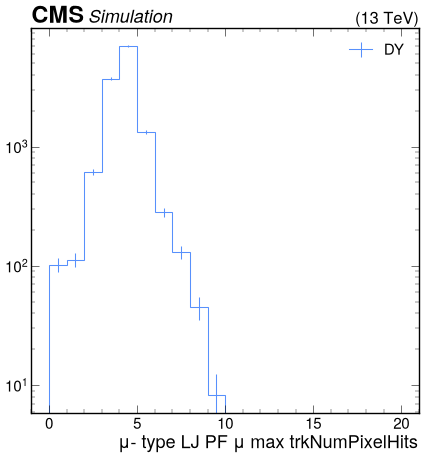

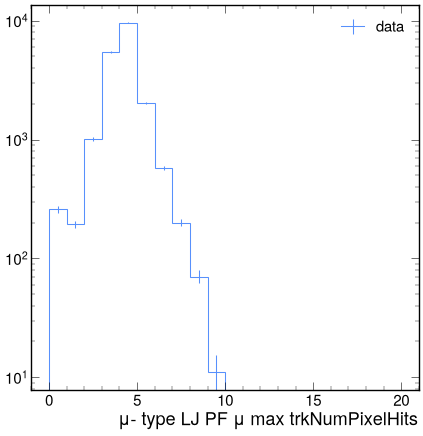

In [8]:
import matplotlib.pyplot as plt
# utilities.plot(sum_bg_qcd, label ="QCD")
plt.figure()
utilities.plot(sum_bg_dy, label ="DY")
plt.legend()
# utilities.plot(sum_bg_db, label ="Diboson")
plt.yscale("log")
plt.figure()
utilities.plot(data_hist, label ="data", skip_label=True)
plt.legend()
plt.yscale("log")
plt.show()

In [ ]:
edges = sum_bg_dy.axes[0].edges
values = sum_bg_dy.values()
for i, value in enumerate(values):
    print(f"Bin {i}: [{edges[i]}, {edges[i+1]}) -> {value}")

In [ ]:
sum_dy_displaced =  sum_bg_dy.values()[:3].sum()
sum_dy_prompt=  sum_bg_dy.values()[3:].sum()
print(sum_dy_prompt)
print(sum_dy_displaced)
ratio = sum_dy_displaced/sum_dy_prompt
print(ratio)

In [ ]:
data_displaced =  data_hist.values()[:3].sum()
data_prompt=  data_hist.values()[3:].sum()
print(f"prompt data: {data_prompt}")
print(f"displaced data: {data_displaced}")
ratio =data_displaced/data_prompt
print(f"ratio: {ratio}")

In [ ]:
sum_qcd_displaced = sum_bg_qcd.values()[:3].sum()
sum_qcd_prompt = sum_bg_qcd.values()[3:].sum()

print(f"QCD prompt: {sum_qcd_prompt}")
print(f"QCD displaced: {sum_qcd_displaced}")

ratio = sum_qcd_displaced / sum_qcd_prompt
print(f"QCD displaced/prompt ratio: {ratio}")

In [ ]:
sum_db_displaced = sum_bg_db.values()[:3].sum()
sum_db_prompt = sum_bg_db.values()[3:].sum()

print(f"DB prompt: {sum_db_prompt}")
print(f"DB displaced: {sum_db_displaced}")

ratio = sum_db_displaced / sum_db_prompt
print(f"DB displaced/prompt ratio: {ratio}")

In [ ]:
import matplotlib.pyplot as plt
# utilities.plot(sum_bg_qcd, label ="QCD")
plt.figure()
utilities.plot(sum_bg_dy, label ="DY")
plt.legend()
# utilities.plot(sum_bg_db, label ="Diboson")
plt.yscale("log")
plt.figure()
utilities.plot(data_hist, label ="data", skip_label=True)
plt.legend()
plt.yscale("log")
plt.show()